# Region Axis / Orientation Consistency Matrix

This notebook explains the **first family** of the current matrix: region / axis / orientation / consistency. It is not redesigning the model. It is reading the implemented `evaluate_scene()` rows and showing what the current scheme already says.

Model objects in the figure:

- **Pale blue polygons** = inferred or authored regions, 区域 after grouping furniture and affordance extents.
- **Green dashed boxes** = furniture groups, the local units whose frames feed region axes.
- **Blue lines** = primary region axes; **blue dashed lines** = secondary axes.
- **Red line** = global region-centroid trend, a PCA-style dominant direction over region centers.
- **Purple lines** = authored column axes when the SVG provides them.

The rough idea: furniture affordance extents form furniture groups; furniture-group frames are averaged into a region frame; region frames can then be compared with other regions, boundaries, and the column grid. Some parts are clean geometry; some are deliberately proxy-ish because perception is not fully decided yet.


## Metrics / 指标说明

The table below is intentionally short: it names the implemented row or evidence field, what it describes, what objects it touches, and how to read the value.

In [1]:

from pathlib import Path
from html import escape
from math import cos, radians, sin

import pandas as pd
from IPython.display import SVG, display

from features.scene_loader import load_structured_svg_scene
from features.scene_evaluator import evaluate_scene

FIXTURES = [
    Path("test/SVG_baseline.svg"),
    Path("test/SVG_oblique.svg"),
    Path("test/SVG_chaoticsvg.svg"),
]

AXIS_METRICS = [
    "inferred_region_count",
    "region_axis_agreement",
    "region_centroid_phase_alignment",
    "region_centroid_trend_alignment",
    "region_boundary_axis_agreement",
    "region_source_boundary_axis_agreement",
    "region_source_boundary_weighted_axis_agreement",
    "region_source_boundary_proximity",
    "region_column_axis_agreement",
    "region_column_bay_fit",
]

METRIC_NOTES = [
    {
        "metric": "inferred_region_count",
        "describes": "How many regions the current inference layer produced.",
        "objects": "furniture groups + affordance extents + boundary cues",
        "logic": "count(inferred_regions)",
        "reading": "More is not automatically better; it tells us what the downstream axis model sees.",
    },
    {
        "metric": "region_axis_agreement",
        "describes": "Whether region axes point in a shared orientation family.",
        "objects": "regions -> axis-angle",
        "logic": "length(mean([cos(2a), sin(2a)]))",
        "reading": "1 means axes are very consistent; 0 means scattered.",
    },
    {
        "metric": "region_centroid_phase_alignment",
        "describes": "Whether region centers are regularly spaced along the mean region axis.",
        "objects": "region centroids + mean axis",
        "logic": "1 / (1 + std(gaps) / mean(gaps))",
        "reading": "Higher means more even phase / spacing between regions.",
    },
    {
        "metric": "region_centroid_trend_alignment",
        "describes": "Whether region centers form a readable global trend line.",
        "objects": "region centroids -> PCA trend axis",
        "logic": "1 / (1 + mean cross-axis deviation / trend span)",
        "reading": "Higher means region centers sit close to one dominant trend.",
    },
    {
        "metric": "region_boundary_axis_agreement",
        "describes": "Whether each region axis can find a nearby boundary-like direction.",
        "objects": "region axes + boundary axes",
        "logic": "mean(max(abs(cos(2 * angle_delta))))",
        "reading": "Higher means regions echo boundary orientation.",
    },
    {
        "metric": "region_source_boundary_axis_agreement",
        "describes": "Same as boundary agreement, but only boundaries scoped to the same region.",
        "objects": "region axes + same-region boundary axes",
        "logic": "mean(best same-region axis similarity)",
        "reading": "Higher means authored local boundary cues support the region direction.",
    },
    {
        "metric": "region_source_boundary_weighted_axis_agreement",
        "describes": "Boundary agreement weighted by boundary length and grouping strength.",
        "objects": "region axes + same-region weighted boundaries",
        "logic": "weighted mean(axis similarity, length * grouping_strength)",
        "reading": "Higher means stronger/longer boundaries pull in the same direction.",
    },
    {
        "metric": "region_source_boundary_proximity",
        "describes": "Whether same-region boundaries are physically close enough to matter.",
        "objects": "region bbox + same-region boundary bbox",
        "logic": "weighted mean(1 / (1 + gap / region_scale))",
        "reading": "Higher means boundary cues are close; it is still a bbox proxy.",
    },
    {
        "metric": "region_column_axis_agreement",
        "describes": "Whether region axes align with authored column-grid axes.",
        "objects": "region axes + column axes",
        "logic": "mean(best region-to-column axis similarity)",
        "reading": "Higher means regions share the building grid's direction.",
    },
    {
        "metric": "region_column_bay_fit",
        "describes": "Whether region bboxes fit adjacent column-axis bays.",
        "objects": "region bbox + authored column-axis bay",
        "logic": "region/bay overlap proxy",
        "reading": "Higher means a region sits more legibly inside a column-grid bay.",
    },
]


def rect_attrs(rect):
    """Return SVG rectangle attributes from the project Rect object."""
    return f'x="{rect.left:.1f}" y="{rect.top:.1f}" width="{rect.width:.1f}" height="{rect.height:.1f}"'


def points_attr(points):
    """Return an SVG point list for polygon records."""
    return " ".join(f"{x:.1f},{y:.1f}" for x, y in points)


def axis_segment(rect, angle, scale=0.42):
    """Create a centered line segment in a region's local axis direction."""
    half = max(rect.width, rect.height) * scale
    dx, dy = cos(radians(angle)) * half, sin(radians(angle)) * half
    return rect.cx - dx, rect.cy - dy, rect.cx + dx, rect.cy + dy


def analysis_regions(scene, matrix):
    """Return the same broad region set that the public matrix explains."""
    return list(scene.get("regions", [])) + list(matrix.get("inferred_regions", []))


def axis_model_overlay(scene, matrix):
    """Draw only the region-axis model layers needed by this notebook."""
    layers = []
    regions = analysis_regions(scene, matrix)

    for region in regions:
        label = escape(region["id"])
        if region.get("points"):
            layers.append(
                f'<polygon points="{points_attr(region["points"])}" fill="#dbeafe" opacity="0.42" '
                f'stroke="#2563eb" stroke-width="1.8"><title>{label}</title></polygon>'
            )
        else:
            layers.append(
                f'<rect {rect_attrs(region["rect"])} fill="#dbeafe" opacity="0.34" '
                f'stroke="#2563eb" stroke-width="1.8"><title>{label}</title></rect>'
            )
        md = region.get("metadata", {})
        if "axis-angle" in md:
            angle = float(md.get("axis-angle", 0.0) or 0.0)
            secondary = float(md.get("secondary-axis-angle", (angle + 90.0) % 180.0) or 0.0)
            x1, y1, x2, y2 = axis_segment(region["rect"], angle)
            sx1, sy1, sx2, sy2 = axis_segment(region["rect"], secondary, scale=0.28)
            layers.append(
                f'<line x1="{x1:.1f}" y1="{y1:.1f}" x2="{x2:.1f}" y2="{y2:.1f}" '
                f'stroke="#1d4ed8" stroke-width="3"><title>{label} primary axis {angle:.1f}</title></line>'
            )
            layers.append(
                f'<line x1="{sx1:.1f}" y1="{sy1:.1f}" x2="{sx2:.1f}" y2="{sy2:.1f}" '
                f'stroke="#38bdf8" stroke-width="2" stroke-dasharray="7 5"><title>{label} secondary axis</title></line>'
            )
        layers.append(f'<text x="{region["rect"].cx:.1f}" y="{region["rect"].cy:.1f}" font-size="11" text-anchor="middle" fill="#172554">{label}</text>')

    for group in matrix.get("furniture_groups", []):
        layers.append(
            f'<rect {rect_attrs(group["rect"])} fill="none" stroke="#059669" stroke-width="1.6" '
            f'stroke-dasharray="4 4" opacity="0.72"><title>{escape(group["id"])}</title></rect>'
        )

    for column in scene.get("column_axes", []):
        if column.get("points") and len(column["points"]) >= 2:
            (x1, y1), (x2, y2) = column["points"][0], column["points"][-1]
        else:
            x1, y1, x2, y2 = axis_segment(column["rect"], float(column.get("metadata", {}).get("axis-angle", 0.0) or 0.0), scale=0.55)
        layers.append(
            f'<line x1="{x1:.1f}" y1="{y1:.1f}" x2="{x2:.1f}" y2="{y2:.1f}" '
            f'stroke="#7c3aed" stroke-width="2.2" opacity="0.75"><title>{escape(column["id"])}</title></line>'
        )

    trend = next((row for row in matrix["rows"] if row["metric"] == "region_centroid_trend_alignment" and row["status"] == "computed"), None)
    if trend:
        centers = [(region["rect"].cx, region["rect"].cy) for region in regions if region["rect"].width > 0 and region["rect"].height > 0]
        if centers:
            cx = sum(x for x, _ in centers) / len(centers)
            cy = sum(y for _, y in centers) / len(centers)
            angle = trend["trend_axis"]["angle"]
            half = max(120.0, trend["trend_axis"].get("span", 250.0) / 2)
            dx, dy = cos(radians(angle)) * half, sin(radians(angle)) * half
            layers.append(
                f'<line x1="{cx-dx:.1f}" y1="{cy-dy:.1f}" x2="{cx+dx:.1f}" y2="{cy+dy:.1f}" '
                f'stroke="#dc2626" stroke-width="3.2" opacity="0.82"><title>global centroid trend {angle:.1f}</title></line>'
            )

    legend = """
    <g transform="translate(24,24)">
      <rect x="0" y="0" width="278" height="92" fill="white" opacity="0.86" stroke="#ddd" />
      <text x="12" y="22" font-size="13" fill="#111">Legend</text>
      <line x1="12" y1="38" x2="52" y2="38" stroke="#1d4ed8" stroke-width="3"/><text x="62" y="42" font-size="12">region primary axis</text>
      <line x1="12" y1="56" x2="52" y2="56" stroke="#dc2626" stroke-width="3"/><text x="62" y="60" font-size="12">global centroid trend</text>
      <rect x="12" y="69" width="38" height="14" fill="none" stroke="#059669" stroke-dasharray="4 4"/><text x="62" y="82" font-size="12">furniture group</text>
    </g>
    """
    return '<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 1000 1000" width="1000" height="1000">' + "".join(layers) + legend + "</svg>"


def metric_rows(matrix):
    """Return only axis/orientation-family rows for compact display."""
    rows = []
    for row in matrix["rows"]:
        if row["metric"] in AXIS_METRICS:
            rows.append({
                "metric": row["metric"],
                "view": row["view_id"],
                "score": row.get("score"),
                "status": row.get("status"),
                "method": row.get("method"),
            })
    return pd.DataFrame(rows)


## Analysis Model + Current Matrix Rows

Each fixture below shows the model layer first, then the implemented metric rows/evidence. The visuals are diagnostic, not a new source of truth.

,metric,describes,objects,logic,reading
0,inferred_region_count,How many regions the current inference layer p...,furniture groups + affordance extents + bounda...,count(inferred_regions),More is not automatically better; it tells us ...
1,region_axis_agreement,Whether region axes point in a shared orientat...,regions -> axis-angle,"length(mean([cos(2a), sin(2a)]))",1 means axes are very consistent; 0 means scat...
2,region_centroid_phase_alignment,Whether region centers are regularly spaced al...,region centroids + mean axis,1 / (1 + std(gaps) / mean(gaps)),Higher means more even phase / spacing between...
3,region_centroid_trend_alignment,Whether region centers form a readable global ...,region centroids -> PCA trend axis,1 / (1 + mean cross-axis deviation / trend span),Higher means region centers sit close to one d...
4,region_boundary_axis_agreement,Whether each region axis can find a nearby bou...,region axes + boundary axes,mean(max(abs(cos(2 * angle_delta)))),Higher means regions echo boundary orientation.
5,region_source_boundary_axis_agreement,"Same as boundary agreement, but only boundarie...",region axes + same-region boundary axes,mean(best same-region axis similarity),Higher means authored local boundary cues supp...
6,region_source_boundary_weighted_axis_agreement,Boundary agreement weighted by boundary length...,region axes + same-region weighted boundaries,"weighted mean(axis similarity, length * groupi...",Higher means stronger/longer boundaries pull i...
7,region_source_boundary_proximity,Whether same-region boundaries are physically ...,region bbox + same-region boundary bbox,weighted mean(1 / (1 + gap / region_scale)),Higher means boundary cues are close; it is st...
8,region_column_axis_agreement,Whether region axes align with authored column...,region axes + column axes,mean(best region-to-column axis similarity),Higher means regions share the building grid's...
9,region_column_bay_fit,Whether region bboxes fit adjacent column-axis...,region bbox + authored column-axis bay,region/bay overlap proxy,Higher means a region sits more legibly inside...


SVG_baseline.svg: regions=5 furniture_groups=5


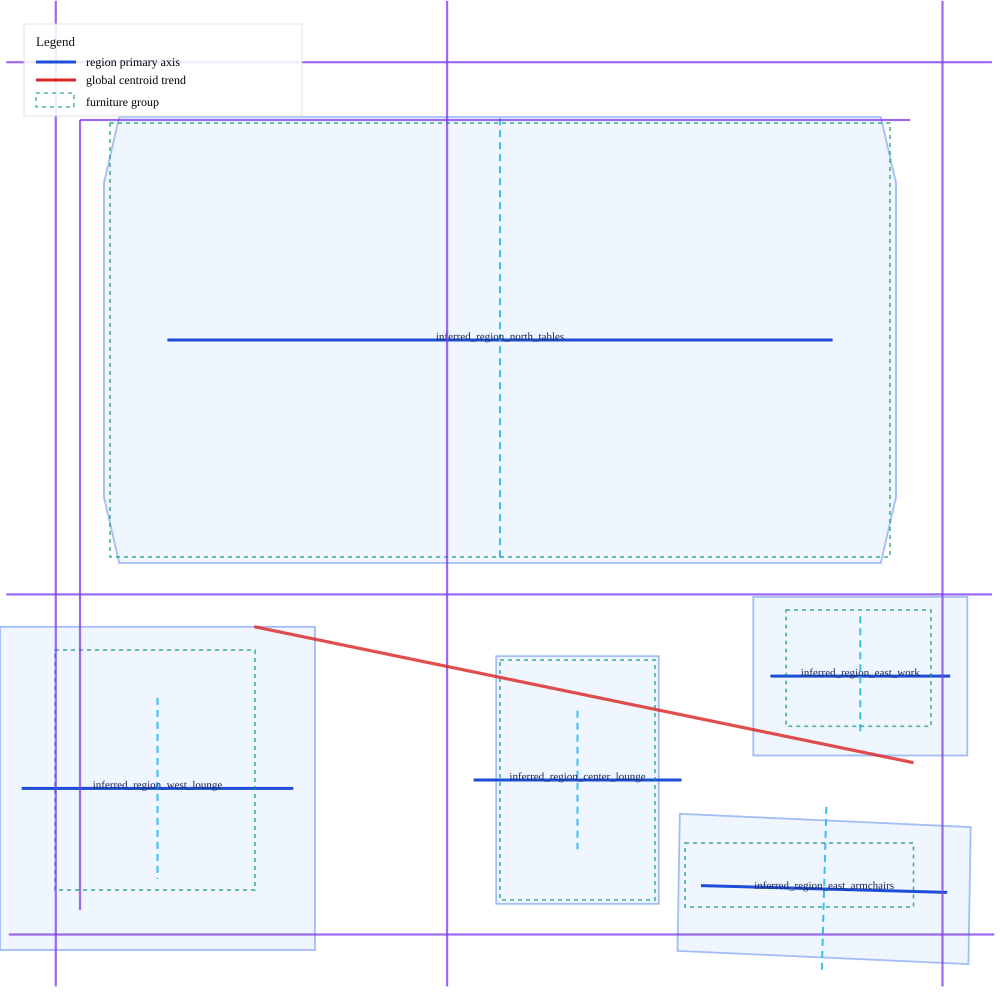

,metric,view,score,status,method
0,region_axis_agreement,region_alignment,0.9998,computed,region_local_axis_consistency
1,region_centroid_phase_alignment,region_alignment,0.5869,computed,region_centroid_projection_gap_cv_score
2,region_centroid_trend_alignment,trend,0.8062,computed,region_centroid_pca_axis_cross_deviation_score
3,region_boundary_axis_agreement,region_alignment,0.9997,computed,region_axis_to_boundary_axis_similarity
4,region_source_boundary_axis_agreement,region_alignment,NaN,not_available,not_available
5,region_source_boundary_weighted_axis_agreement,region_alignment,NaN,not_available,not_available
6,region_source_boundary_proximity,region_alignment,NaN,not_available,not_available
7,inferred_region_count,region_alignment,5.0000,computed,affordance_zone_boundary_cue_expanded_group_bo...
8,region_column_axis_agreement,column_alignment,0.9997,computed,region_bbox_axis_to_column_axis_similarity
9,region_column_bay_fit,column_alignment,0.9349,computed,region_bbox_overlap_with_adjacent_column_axis_bay


SVG_oblique.svg: regions=5 furniture_groups=5


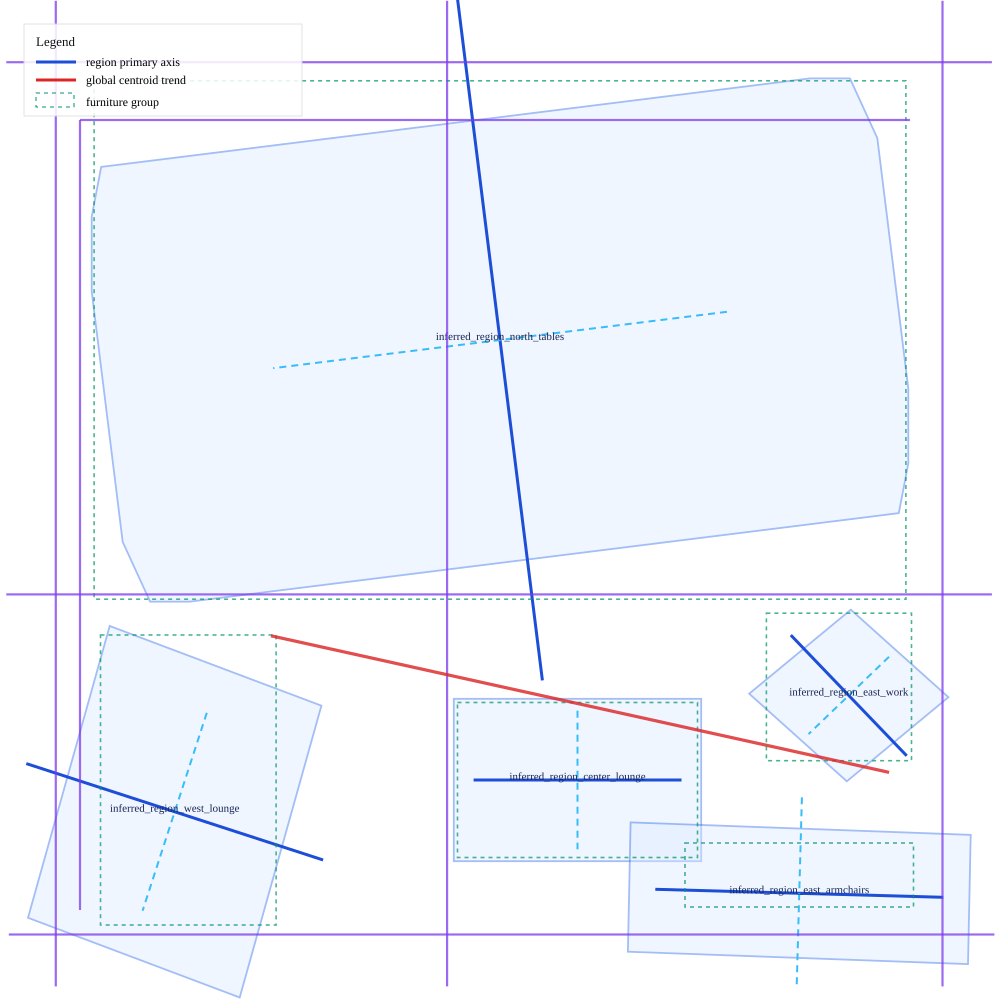

,metric,view,score,status,method
0,region_axis_agreement,region_alignment,0.5212,computed,region_local_axis_consistency
1,region_centroid_phase_alignment,region_alignment,0.5945,computed,region_centroid_projection_gap_cv_score
2,region_centroid_trend_alignment,trend,0.7964,computed,region_centroid_pca_axis_cross_deviation_score
3,region_boundary_axis_agreement,region_alignment,0.7636,computed,region_axis_to_boundary_axis_similarity
4,region_source_boundary_axis_agreement,region_alignment,NaN,not_available,not_available
5,region_source_boundary_weighted_axis_agreement,region_alignment,NaN,not_available,not_available
6,region_source_boundary_proximity,region_alignment,NaN,not_available,not_available
7,inferred_region_count,region_alignment,5.0000,computed,affordance_zone_boundary_cue_expanded_group_bo...
8,region_column_axis_agreement,column_alignment,0.7636,computed,region_bbox_axis_to_column_axis_similarity
9,region_column_bay_fit,column_alignment,0.8925,computed,region_bbox_overlap_with_adjacent_column_axis_bay


SVG_chaoticsvg.svg: regions=5 furniture_groups=5


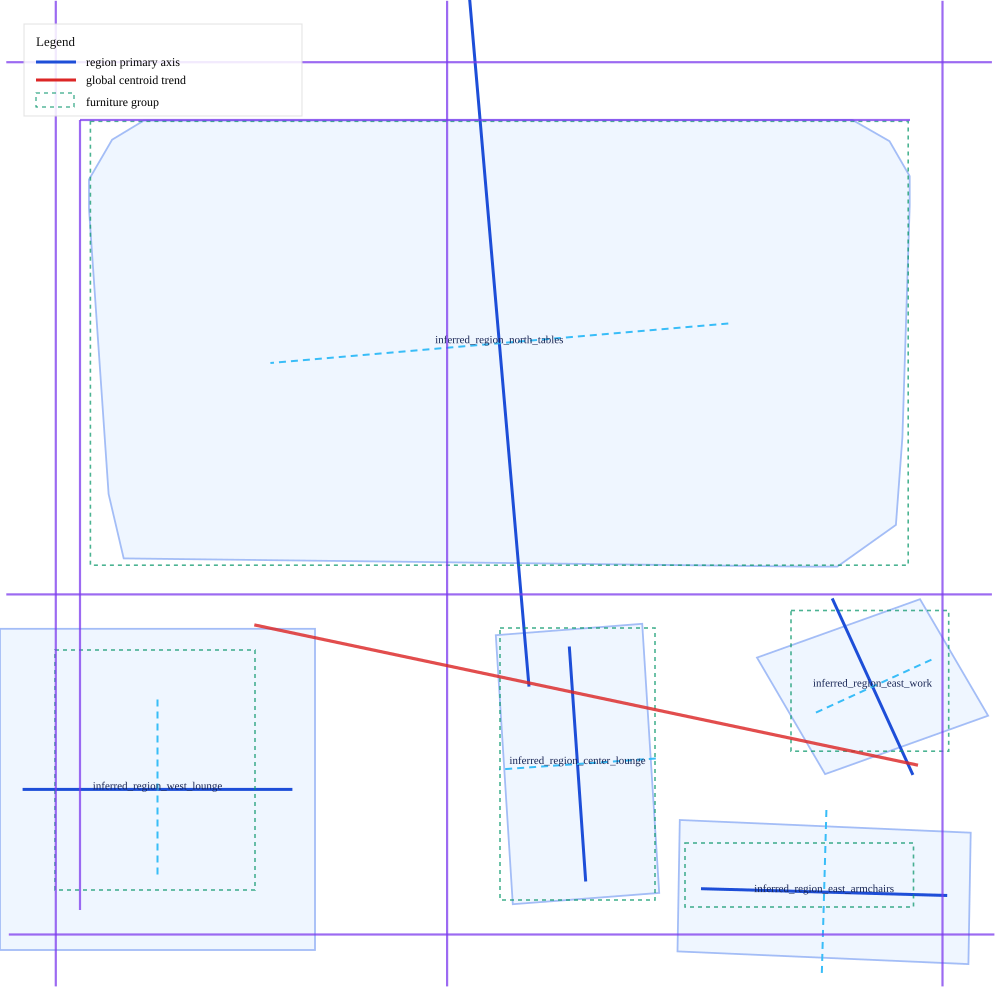

,metric,view,score,status,method
0,region_axis_agreement,region_alignment,0.2576,computed,region_local_axis_consistency
1,region_centroid_phase_alignment,region_alignment,0.7081,computed,region_centroid_projection_gap_cv_score
2,region_centroid_trend_alignment,trend,0.8116,computed,region_centroid_pca_axis_cross_deviation_score
3,region_boundary_axis_agreement,region_alignment,0.9256,computed,region_axis_to_boundary_axis_similarity
4,region_source_boundary_axis_agreement,region_alignment,NaN,not_available,not_available
5,region_source_boundary_weighted_axis_agreement,region_alignment,NaN,not_available,not_available
6,region_source_boundary_proximity,region_alignment,NaN,not_available,not_available
7,inferred_region_count,region_alignment,5.0000,computed,affordance_zone_boundary_cue_expanded_group_bo...
8,region_column_axis_agreement,column_alignment,0.9256,computed,region_bbox_axis_to_column_axis_similarity
9,region_column_bay_fit,column_alignment,0.9346,computed,region_bbox_overlap_with_adjacent_column_axis_bay


In [2]:

display(pd.DataFrame(METRIC_NOTES))

for path in FIXTURES:
    scene = load_structured_svg_scene(path)
    matrix = evaluate_scene(scene)
    print(f"{path.name}: regions={len(analysis_regions(scene, matrix))} furniture_groups={len(matrix.get('furniture_groups', []))}")
    display(SVG(data=axis_model_overlay(scene, matrix)))
    display(metric_rows(matrix))
